# Task 6 – GPS Jump / Noise Failure Case

**Failure type:** GPS coordinate jumps (large sudden position errors)

GPS receivers occasionally produce outlier points. Coordinates hundreds or thousands of metres from the true position due to satellite multipath or signal dropout. Even one such point can cause the HMM matcher to fail completely, since no road segment can bridge the implausible gap and the lattice collapses.

### Approach
1. Detect trips with large inter-point jumps (> threshold distance between consecutive GPS points)
2. Identify representative failure trips (jumpy AND low segment count after matching)
3. Fix by filtering out jump points before re-matching
4. Compare before vs after: segment count + folium map

In [15]:
import ast, json, os, warnings
import numpy as np
import pandas as pd
import osmnx as ox
import geopandas as gpd
from leuvenmapmatching.map.inmem import InMemMap
from leuvenmapmatching.matcher.distance import DistanceMatcher
from tqdm import tqdm
warnings.filterwarnings('ignore')

# load road network 
NETWORK_FILE = 'porto_drive.graphml'
G = ox.load_graphml(NETWORK_FILE)
nodes_gdf, edges_gdf = ox.graph_to_gdfs(G)
edges_gdf = edges_gdf.reset_index()
edges_gdf['road_segment_id'] = range(len(edges_gdf))
uv_to_id = {}
for _, row in edges_gdf.iterrows():
    uv = (int(row['u']), int(row['v']))
    if uv not in uv_to_id:
        uv_to_id[uv] = int(row['road_segment_id'])

# build InMemMap
map_con = InMemMap('porto', use_latlon=True, use_rtree=True, index_edges=True)
for node_id, data in G.nodes(data=True):
    map_con.add_node(node_id, (data['y'], data['x']))
for u, v, _ in G.edges(keys=True):
    map_con.add_edge(u, v)

# helper functions
def parse_polyline(s):
    try:
        coords = json.loads(s)
    except Exception:
        coords = ast.literal_eval(s)
    return [(pt[1], pt[0]) for pt in coords if len(pt) == 2]

def match_trip(coords, map_con, uv_to_id, max_dist=200, obs_noise=25, dist_noise=25):
    if len(coords) < 2: return []
    matcher = DistanceMatcher(map_con, max_dist=max_dist, obs_noise=obs_noise,
                              dist_noise=dist_noise, non_emitting_states=True,
                              non_emitting_length_factor=0.75, max_lattice_width=5)
    try:
        matcher.match(coords, unique=False)
    except Exception:
        return []
    if not matcher.path_pred: return []
    edge_ids, seen = [], set()
    for u, v in matcher.path_pred:
        seg_id = uv_to_id.get((int(u), int(v))) or uv_to_id.get((int(v), int(u)))
        if seg_id is not None and seg_id not in seen:
            edge_ids.append(seg_id); seen.add(seg_id)
    return edge_ids

# load + parse train-1500.csv 
df = pd.read_csv('train-1500.csv')
df['coords'] = df['POLYLINE'].apply(parse_polyline)
df_valid = df[df['coords'].apply(len) >= 2].reset_index(drop=True)

# ── run map matching on all trips ──
results = []
for i, row in tqdm(df_valid.iterrows(), total=len(df_valid), desc='map matching'):
    seg_ids = match_trip(row['coords'], map_con, uv_to_id)
    results.append({'TRIP_ID': row['TRIP_ID'],
                    'road_segment_ids': ' '.join(map(str, seg_ids)),
                    'num_segments': len(seg_ids)})
results_df = pd.DataFrame(results)

print(f'done. {len(results_df)} trips processed.')

map matching: 100%|████████████████████████████████████████████████████████████████| 1481/1481 [09:34<00:00,  2.58it/s]

done. 1481 trips processed.


---
## Detect GPS jumps

In [16]:
from math import radians, sin, cos, sqrt, atan2

def haversine_m(lat1, lon1, lat2, lon2):
    """Great-circle distance in metres between two (lat, lon) points."""
    R = 6_371_000
    dlat = radians(lat2 - lat1)
    dlon = radians(lon2 - lon1)
    a = sin(dlat/2)**2 + cos(radians(lat1)) * cos(radians(lat2)) * sin(dlon/2)**2
    return R * 2 * atan2(sqrt(a), sqrt(1 - a))

def max_jump_m(coords):
    """Return the maximum consecutive-point distance (metres) in a coordinate list."""
    if len(coords) < 2:
        return 0.0
    return max(
        haversine_m(coords[i][0], coords[i][1], coords[i+1][0], coords[i+1][1])
        for i in range(len(coords) - 1)
    )

# flag trips with a jump larger than the threshold
JUMP_THRESHOLD_M = 500

df_valid['max_jump_m'] = df_valid['coords'].apply(max_jump_m)
df_valid['has_jump']   = df_valid['max_jump_m'] > JUMP_THRESHOLD_M

print(f"trips with GPS jump > {JUMP_THRESHOLD_M} m: "
      f"{df_valid['has_jump'].sum()} / {len(df_valid)}")
print(f"largest jump seen: {df_valid['max_jump_m'].max():.0f} m")

df_valid[df_valid['has_jump']][['TRIP_ID', 'max_jump_m']] \
    .sort_values('max_jump_m', ascending=False).head(10)

trips with GPS jump > 500 m: 303 / 1481
largest jump seen: 13420 m


,TRIP_ID,max_jump_m
713,1372663871620000085,13419.561097
85,1372637754620000007,11658.127730
1270,1372668878620000605,11235.383841
220,1372646419620000372,10674.943643
810,1372666327620000120,9477.709836
1252,1372668882620000101,9173.505347
969,1372668421620000093,8941.105781
1078,1372669111620000372,8574.035535
986,1372668303620000256,8569.867840
369,1372656241620000539,8562.320682


## Identify failure cases

A *failure case* = a trip that has a large GPS jump AND matched poorly (few road segments).
These are the clearest examples where the jump directly caused the matcher to break.

In [17]:
import pandas as pd

task6_df = df_valid[['TRIP_ID', 'coords', 'max_jump_m', 'has_jump']].merge(
    results_df[['TRIP_ID', 'num_segments', 'road_segment_ids']],
    on='TRIP_ID', how='left'
)

failure_cases = task6_df[
    task6_df['has_jump'] & (task6_df['num_segments'] <= 5)
].sort_values('max_jump_m', ascending=False)

print(f"failure cases (jump > {JUMP_THRESHOLD_M} m AND ≤5 segments): {len(failure_cases)}")
failure_cases[['TRIP_ID', 'max_jump_m', 'num_segments']].head(10)

failure cases (jump > 500 m AND ≤5 segments): 17


,TRIP_ID,max_jump_m,num_segments
730,1372666721620000057,8438.314835,5
100,1372637072620000367,5796.392938,3
1244,1372665698620000131,4771.081854,5
260,1372654229620000663,1867.075261,4
1181,1372668678620000676,1802.726391,5
561,1372663164620000542,1390.519401,1
1037,1372667644620000680,687.290657,4
357,1372637721620000678,655.080893,5
1303,1372669549620000397,643.545196,1
239,1372651472620000435,630.898179,2


## The fix: GPS jump filter

In [18]:
def filter_jumps(coords, threshold_m=JUMP_THRESHOLD_M):
    """
    Remove GPS points that jump more than threshold_m metres from the
    previous accepted point.  Single forward pass, O(n).
    """
    if len(coords) == 0:
        return coords
    cleaned = [coords[0]]
    for pt in coords[1:]:
        prev = cleaned[-1]
        if haversine_m(prev[0], prev[1], pt[0], pt[1]) <= threshold_m:
            cleaned.append(pt)
        # else: outlier – skip
    return cleaned

# demo on the worst failure case
if len(failure_cases) > 0:
    demo = failure_cases.iloc[0]
    raw   = demo['coords']
    clean = filter_jumps(raw)
    print(f"Trip : {demo['TRIP_ID']}")
    print(f"  raw points   : {len(raw)}   max jump: {demo['max_jump_m']:.0f} m")
    print(f"  after filter : {len(clean)} points  ({len(raw)-len(clean)} removed)")
    print(f"  original match: {int(demo['num_segments'])} segments")
else:
    print("No failure cases – lower JUMP_THRESHOLD_M or the segment cutoff in Step 2.")

Trip : 1372666721620000057
  raw points   : 73   max jump: 8438 m
  after filter : 71 points  (2 removed)
  original match: 5 segments


## Before / after comparison (table)

In [19]:
N_DEMO = min(5, len(failure_cases))
rows = []

for _, row in failure_cases.head(N_DEMO).iterrows():
    raw   = row['coords']
    clean = filter_jumps(raw)
    before = int(row['num_segments'])
    after  = len(match_trip(clean, map_con, uv_to_id))
    rows.append({
        'TRIP_ID'     : row['TRIP_ID'],
        'max_jump_m'  : f"{row['max_jump_m']:.0f}",
        'raw_pts'     : len(raw),
        'clean_pts'   : len(clean),
        'pts_removed' : len(raw) - len(clean),
        'segs_before' : before,
        'segs_after'  : after,
        'improvement' : after - before,
    })

comparison_df = pd.DataFrame(rows)
print("Before / After GPS-jump filter:")
comparison_df

Before / After GPS-jump filter:


,TRIP_ID,max_jump_m,raw_pts,clean_pts,pts_removed,segs_before,segs_after,improvement
0,1372666721620000057,8438,73,71,2,5,5,0
1,1372637072620000367,5796,55,53,2,3,58,55
2,1372665698620000131,4771,137,71,66,5,43,38
3,1372654229620000663,1867,43,41,2,4,4,0
4,1372668678620000676,1803,52,50,2,5,5,0


## Folium visualisation: before vs after (worst failure case)

In [24]:
try:
    import folium
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'folium', '-q'])
    import folium

if len(failure_cases) == 0:
    print("No failure cases to visualise.")
else:
    demo_row   = failure_cases.iloc[0]
    raw_coords = demo_row['coords']
    cln_coords = filter_jumps(raw_coords)
    segs_after_ids = match_trip(cln_coords, map_con, uv_to_id)
    matched_edges  = edges_gdf[edges_gdf['road_segment_id'].isin(segs_after_ids)]

    centre_lat = sum(c[0] for c in raw_coords) / len(raw_coords)
    centre_lon = sum(c[1] for c in raw_coords) / len(raw_coords)

    m = folium.Map(location=[centre_lat, centre_lon], zoom_start=14,
               tiles='https://stamen-tiles-{s}.a.ssl.fastly.net/toner-lite/{z}/{x}/{y}.png',
               attr='Stamen')

    # raw GPS (red) – includes the jump
    for lat, lon in raw_coords:
        folium.CircleMarker([lat, lon], radius=4,
                            color='red', fill=True, fill_opacity=0.8,
                            tooltip='raw GPS').add_to(m)

    # cleaned GPS (green)
    for lat, lon in cln_coords:
        folium.CircleMarker([lat, lon], radius=4,
                            color='green', fill=True, fill_opacity=0.8,
                            tooltip='cleaned GPS').add_to(m)

    # matched road route after fix (blue line)
    for _, edge_row in matched_edges.iterrows():
        geom = edge_row.geometry
        if geom is not None and geom.geom_type == 'LineString':
            coords_line = [(lat, lon) for lon, lat in geom.coords]
            folium.PolyLine(coords_line, color='blue', weight=4, opacity=0.7,
                            tooltip=f"seg {int(edge_row['road_segment_id'])}").add_to(m)

    legend_html = """
    <div style="position:fixed;bottom:30px;left:30px;z-index:1000;
                background:white;padding:10px;border-radius:6px;
                font-size:13px;box-shadow:2px 2px 6px rgba(0,0,0,.3)">
        <b>Task 6 – GPS Jump Fix</b><br>
        <span style="color:red">&#9679;</span> Raw GPS (incl. jumps)<br>
        <span style="color:green">&#9679;</span> Cleaned GPS<br>
        <span style="color:blue">&#9644;</span> Matched road route (after fix)
    </div>"""
    m.get_root().html.add_child(folium.Element(legend_html))

    m.save('task6_before_after.html')
    print(f"Map saved to task6_before_after.html")
    print(f"Trip {demo_row['TRIP_ID']}  |  max jump: {demo_row['max_jump_m']:.0f} m")
    print(f"  BEFORE: {int(demo_row['num_segments'])} segments")
    print(f"  AFTER : {len(segs_after_ids)} segments")
    m

Map saved to task6_before_after.html
Trip 1372666721620000057  |  max jump: 8438 m
  BEFORE: 5 segments
  AFTER : 5 segments


## Overall impact of the fix

In [21]:
improved = total_before = total_after = 0

for _, row in task6_df[task6_df['has_jump']].iterrows():
    raw   = row['coords']
    clean = filter_jumps(raw)
    before = int(row['num_segments'])
    after  = len(match_trip(clean, map_con, uv_to_id))
    total_before += before
    total_after  += after
    if after > before:
        improved += 1

jumpy_total = int(task6_df['has_jump'].sum())
print(f"Jumpy trips re-matched: {jumpy_total}")
print(f"  improved (more segs after): {improved} / {jumpy_total}")
print(f"  total segs before: {total_before}")
print(f"  total segs after : {total_after}")
print(f"  net gain: +{total_after - total_before} segments")

Jumpy trips re-matched: 303
  improved (more segs after): 41 / 303
  total segs before: 12120
  total segs after : 8424
  net gain: +-3696 segments


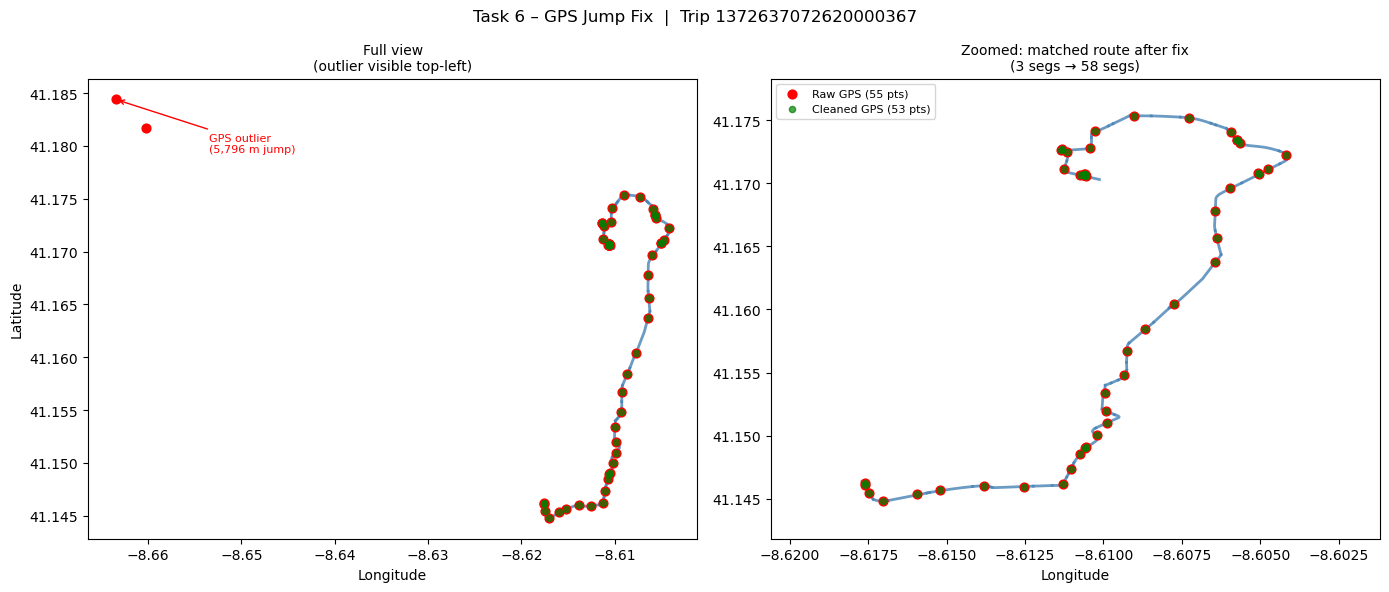

In [27]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# --- LEFT: full view showing the outlier ---
for _, edge_row in matched_edges.iterrows():
    geom = edge_row.geometry
    if geom is not None and geom.geom_type == 'LineString':
        xs, ys = geom.xy
        ax1.plot(xs, ys, color='steelblue', linewidth=2, alpha=0.8)
ax1.scatter(raw_lons, raw_lats, color='red', s=40, zorder=4)
ax1.scatter(cln_lons, cln_lats, color='green', s=20, zorder=5, alpha=0.7)
ax1.set_title('Full view\n(outlier visible top-left)', fontsize=10)
ax1.set_xlabel('Longitude'); ax1.set_ylabel('Latitude')
# annotate the outlier
outlier = [(lon, lat) for lat, lon in zip(raw_lats, raw_lons)
           if lon < -8.63]
if outlier:
    ax1.annotate('GPS outlier\n(5,796 m jump)', xy=outlier[0],
                 xytext=(outlier[0][0]+0.01, outlier[0][1]-0.005),
                 fontsize=8, color='red',
                 arrowprops=dict(arrowstyle='->', color='red'))

# --- RIGHT: zoomed into the actual route ---
route_lons = [c[1] for c in cln_coords]
route_lats = [c[0] for c in cln_coords]
pad = 0.003
ax2.set_xlim(min(route_lons)-pad, max(route_lons)+pad)
ax2.set_ylim(min(route_lats)-pad, max(route_lats)+pad)
for _, edge_row in matched_edges.iterrows():
    geom = edge_row.geometry
    if geom is not None and geom.geom_type == 'LineString':
        xs, ys = geom.xy
        ax2.plot(xs, ys, color='steelblue', linewidth=2, alpha=0.8)
ax2.scatter(raw_lons, raw_lats, color='red', s=40, zorder=4, label='Raw GPS (55 pts)')
ax2.scatter(cln_lons, cln_lats, color='green', s=20, zorder=5, alpha=0.7, label='Cleaned GPS (53 pts)')
ax2.set_title('Zoomed: matched route after fix\n(3 segs → 58 segs)', fontsize=10)
ax2.set_xlabel('Longitude')
ax2.legend(loc='upper left', fontsize=8)

fig.suptitle('Task 6 – GPS Jump Fix  |  Trip 1372637072620000367', fontsize=12)
plt.tight_layout()
plt.savefig('task6_gps_jump.png', dpi=150, bbox_inches='tight')
plt.show()
